# Projet 3 — Q-Learning tabulaire sur `MountainCar-v0`
## Phase 1 : Business Understanding (démarche TDSP)



## 1. Introduction

### 1.1 Contexte et problème

L'apprentissage par renforcement (*Reinforcement Learning*, RL) étudie comment un agent apprend à décider par essais et erreurs, en interagissant avec un environnement et en cherchant à maximiser une récompense cumulée. Le problème **Mountain Car**, introduit par Moore (1990), est un benchmark classique de ce domaine.

Une voiture est placée au fond d'une vallée sinusoïdale. Son moteur est trop faible pour gravir directement la colline de droite, où se trouve le drapeau. La seule solution est d'**osciller** : monter un peu à gauche, redescendre, puis aborder la pente de droite avec l'élan accumulé. L'agent ignore tout de cette physique et doit découvrir la stratégie seul.

Formellement, c'est un processus de décision markovien (MDP) :

| Élément | Définition |
|---|---|
| **État** | position et vitesse de la voiture (deux variables continues) |
| **Actions** | accélérer à gauche, ne rien faire, accélérer à droite |
| **Récompense** | −1 à chaque pas : plus l'agent est rapide, meilleur est son score |
| **Fin d'épisode** | position ≥ 0.5 (succès) ou limite de 200 pas |

### 1.2 Difficultés

Ce problème, simple en apparence, réunit trois difficultés centrales du RL :

1. **Récompense éparse.** Le signal est −1 partout. Un agent qui agit au hasard atteint rarement le but, donc il a très peu d'information pour apprendre au début.
2. **État continu.** Le Q-Learning classique manipule une table de valeurs Q(s, a), ce qui impose de **discrétiser** l'état.
3. **Compromis exploration/exploitation.** L'agent doit essayer des actions nouvelles sans abandonner ce qu'il a déjà appris.

### 1.3 Motivation

Mountain Car illustre un principe général du contrôle : une action qui éloigne temporairement du but (reculer) peut être nécessaire pour l'atteindre. Ce type de planification se retrouve en robotique, en conduite autonome et en contrôle de systèmes. Sa petite dimension (2 variables d'état, 3 actions) permet de visualiser et d'interpréter l'apprentissage, ce qui en fait un support pédagogique adapté.

### 1.4 Objectifs du projet

Ce projet suit la démarche TDSP et implémente un **agent Q-Learning tabulaire** avec discrétisation de l'état. Ses objectifs sont :

| # | Objectif | Indicateur | Cible |
|---|---|---|---|
| O1 | L'agent atteint le but | Taux de succès (évaluation greedy) | ≥ 90 % |
| O2 | L'agent est rapide | Récompense moyenne | ≥ −130 |
| O3 | Se rapprocher du seuil officiel | Seuil Gymnasium | −110 |
| O4 | Vérifier que l'apprentissage apporte un gain | Comparaison à l'agent aléatoire | nettement meilleur |
| O5 | Comprendre l'effet des choix | Expériences sur la discrétisation et les hyperparamètres | analyse écrite |
| O6 | Se situer par rapport à l'article | Reproduction de sa configuration | écart expliqué |

> Ces cibles sont fixées **avant** l'expérimentation. Elles seront confrontées aux résultats en phase 4 (*Deployment & Customer Acceptance*).

### 1.5 Critères de succès et contraintes

Le succès est jugé sur la **récompense cumulée**, le **taux de succès**, le **nombre d'épisodes nécessaires à la convergence** et les **courbes d'apprentissage**, comme demandé par l'énoncé.

Les contraintes sont : la reproductibilité (graines fixées, plusieurs graines par configuration), un temps de calcul raisonnable et un rapport de 20 pages maximum.

### 1.6 Organisation du rapport

Le rapport suit les 4 phases du TDSP :

| Phase TDSP | Sections du rapport |
|---|---|
| 1. Business Understanding | Introduction, Revue de littérature |
| 2. Data Acquisition & Understanding | Description de l'environnement |
| 3. Modeling | Méthodologie, Implémentation, Expériences |
| 4. Deployment & Customer Acceptance | Résultats et discussion, Conclusion |

## 2. Revue de littérature

### 2.1 Article de référence

**Chavali, Kandavalli, Sugash T M, Amudha J.**, *Modelling a Reinforcement Learning Agent for Mountain Car Problem Using Q-Learning With Tabular Discretization*, IEEE MysuruCon 2022.

**Contribution.** Les auteurs résolvent `MountainCar-v0` par Q-Learning tabulaire. L'état est discrétisé en une grille **12 × 12** (Q-table de 12 × 12 × 3), avec exploration ε-greedy et un taux d'apprentissage décroissant. Ils étudient l'effet de quatre hyperparamètres (α, γ, ε, taux de décroissance) en modifiant un paramètre à la fois.

**Résultats.**

| α | decay | ε | γ | Score | Temps |
|---|---|---|---|---|---|
| 0.008 | 100 | 0.01 | 0.55 | −200.0 | 2 h 05 |
| 0.008 | 100 | 0.1 | 0.99 | −166.0 | 3 h 03 |
| 0.05 | 100 | 0.01 | 0.99 | −164.0 | 1 h 59 |
| **0.008** | **100** | **0.01** | **0.99** | **−108.0** | 8 h 46 |
| **0.008** | **10** | 0.01 | 0.99 | **−109.0** | **1 h 42** |

Le meilleur score (−108) dépasse de peu le seuil de résolution (−110). Un γ trop bas (0.55) fait échouer l'agent. Un taux de décroissance plus faible donne presque le même score en cinq fois moins de temps. Les auteurs concluent que la méthode est plus économe en mémoire et en temps que le Q-Learning classique et SARSA.

**Analyse critique.**

- Le nombre d'épisodes, la méthode de calcul du score et les graines ne sont pas précisés, et aucune variance n'est donnée : un écart de 1 point entre −108 et −109 n'est donc pas interprétable.
- Une seule taille de grille est testée, sans justification, alors que la discrétisation est le cœur de la méthode.
- La comparaison avec SARSA et le Q-Learning classique est un tableau qualitatif, sans expérience.
- Le texte situe le point de départ à 0.521, ce qui est incompatible avec la spécification de l'environnement (départ proche de −0.5).
- La revue de littérature de l'article cite des travaux peu liés au sujet.
- Qualifier de « nouvel algorithme » une discrétisation tabulaire avec Q-Learning est excessif, car la méthode est classique.

### 2.2 Travaux voisins

| Travail | Apport | Lien avec le projet |
|---|---|---|
| **Q-Learning** (Watkins & Dayan, 1992) | Algorithme *off-policy* de différence temporelle : Q(s,a) ← Q(s,a) + α [r + γ·max Q(s',a') − Q(s,a)] | Algorithme étudié |
| **SARSA** (Rummery & Niranjan, 1994) | Variante *on-policy* utilisant l'action réellement choisie à l'état suivant | Point de comparaison |
| **Sutton & Barto (2018)** | Cadre théorique : MDP, exploration, convergence | Fondements |
| **Bădică et al. (ACIIDS 2022)** | Physique du problème, discrétisation + Q-Learning | Confirme que le choix de discrétisation est déterminant |
| **DQN** (Mnih et al., 2015) | Remplace la table par un réseau de neurones | Perspective : utile quand l'espace d'états est grand, inutilement lourd ici |
| **OpenAI Gym / Gymnasium** (Brockman et al., 2016 ; Towers et al., 2024) | Fournit `MountainCar-v0` | Environnement |

### 2.3 Positionnement

L'article établit que le Q-Learning tabulaire peut atteindre le seuil de résolution. Notre travail le **complète** sur quatre points :

1. une étude **systématique de la résolution de la grille**, absente de l'article ;
2. **plusieurs graines** par configuration pour quantifier la variabilité ;
3. une **comparaison mesurée** avec SARSA ;
4. une **reproduction de la configuration de l'article** pour situer nos résultats.

## 3. Références

1. Moore, A. W. (1990). *Efficient Memory-based Learning for Robot Control*. PhD thesis, University of Cambridge.
2. Chavali, S. T., Kandavalli, C. T., Sugash T. M., Amudha, J. (2022). Modelling a Reinforcement Learning Agent for Mountain Car Problem Using Q-Learning With Tabular Discretization. *IEEE MysuruCon 2022*. doi:10.1109/MysuruCon55714.2022.9972352
3. Watkins, C. J. C. H., Dayan, P. (1992). Q-learning. *Machine Learning*, 8, 279-292.
4. Rummery, G. A., Niranjan, M. (1994). *On-line Q-learning using connectionist systems*. Technical report, Cambridge University.
5. Sutton, R. S., Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2e éd.). MIT Press.
6. Mnih, V. et al. (2015). Human-level control through deep reinforcement learning. *Nature*, 518, 529-533.
7. Bădică, A., Bădică, C., Ivanović, M., Logofătu, D. (2022). Experiments with Solving Mountain Car Problem Using State Discretization and Q-Learning. *ACIIDS 2022*.
8. Brockman, G. et al. (2016). OpenAI Gym. arXiv:1606.01540.
9. Towers, M. et al. (2024). Gymnasium. arXiv:2407.17032.
10. Documentation Gymnasium, *Mountain Car* : https://gymnasium.farama.org/environments/classic_control/mountain_car/



Phase 2 – Data Acquisition & Understanding

In [1]:
!pip install -q gymnasium

import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

print("Gymnasium version :", gym.__version__)
print("NumPy version :", np.__version__)

Gymnasium version : 1.4.0
NumPy version : 2.4.6


In [2]:
env = gym.make("MountainCar-v0")

print("=== Espace d'observation (l'état) ===")
print(env.observation_space)
print("Bornes basses :", env.observation_space.low)
print("Bornes hautes :", env.observation_space.high)

print("\n=== Espace d'action ===")
print(env.action_space)
print("Nombre d'actions :", env.action_space.n)

print("\n=== Règles de l'épisode ===")
print("Seuil de réussite :", env.spec.reward_threshold)
print("Nombre de pas maximum :", env.spec.max_episode_steps)
print("Position du drapeau :", env.unwrapped.goal_position)

=== Espace d'observation (l'état) ===
Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
Bornes basses : [-1.2  -0.07]
Bornes hautes : [0.6  0.07]

=== Espace d'action ===
Discrete(3)
Nombre d'actions : 3

=== Règles de l'épisode ===
Seuil de réussite : -110.0
Nombre de pas maximum : 200
Position du drapeau : 0.5


In [3]:
# --- Début d'un épisode ---
etat, info = env.reset(seed=0)
print("Etat initial :", etat)
print("  position =", etat[0], "| vitesse =", etat[1])

# --- On fait 5 pas en poussant toujours à droite (action 2) ---
print("\nPas | action | position | vitesse | récompense | terminé | tronqué")
for pas in range(1, 6):
    etat, recompense, termine, tronque, info = env.step(2)
    print(f"{pas:3d} |   2    | {etat[0]:8.4f} | {etat[1]:7.4f} | {recompense:10.1f} | {termine} | {tronque}")

Etat initial : [-0.47260767  0.        ]
  position = -0.47260767 | vitesse = 0.0

Pas | action | position | vitesse | récompense | terminé | tronqué
  1 |   2    |  -0.4720 |  0.0006 |       -1.0 | False | False
  2 |   2    |  -0.4708 |  0.0012 |       -1.0 | False | False
  3 |   2    |  -0.4689 |  0.0018 |       -1.0 | False | False
  4 |   2    |  -0.4665 |  0.0024 |       -1.0 | False | False
  5 |   2    |  -0.4635 |  0.0030 |       -1.0 | False | False


Score moyen (agent aléatoire) : -200.0
Score min / max : -200.0 / -200.0
Taux de succès : 0.0 %


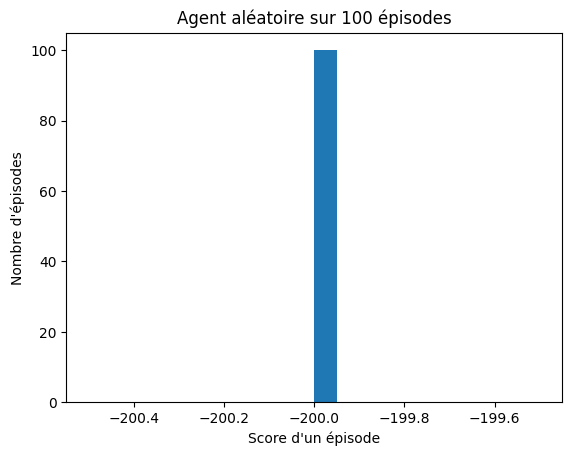

In [4]:
nb_episodes = 100
scores = []
succes = 0

for episode in range(nb_episodes):
    etat, _ = env.reset(seed=episode)
    total = 0
    fini = False
    while not fini:
        action = env.action_space.sample()          # action au hasard
        etat, recompense, termine, tronque, _ = env.step(action)
        total += recompense
        fini = termine or tronque
    scores.append(total)
    if termine:                                      # drapeau atteint
        succes += 1

print("Score moyen (agent aléatoire) :", np.mean(scores))
print("Score min / max :", np.min(scores), "/", np.max(scores))
print("Taux de succès :", succes / nb_episodes * 100, "%")

plt.hist(scores, bins=20)
plt.xlabel("Score d'un épisode")
plt.ylabel("Nombre d'épisodes")
plt.title("Agent aléatoire sur 100 épisodes")
plt.show()

In [5]:
# --- Paramètres de la discrétisation ---
N = 12                                   # nombre d'intervalles par variable
bas  = env.observation_space.low         # [-1.2, -0.07]
haut = env.observation_space.high        # [ 0.6,  0.07]

largeur = (haut - bas) / N
print("Largeur d'un intervalle (position, vitesse) :", largeur)

# --- Fonction de discrétisation ---
def discretiser(etat):
    ratio = (etat - bas) / (haut - bas)          # valeur entre 0 et 1
    indices = (ratio * N).astype(int)            # entier entre 0 et N
    indices = np.clip(indices, 0, N - 1)         # on reste dans 0..N-1
    return tuple(indices)

# --- Test sur quelques états ---
exemples = [
    np.array([-0.5,  0.0 ]),    # fond de la vallée, immobile
    np.array([-1.2, -0.07]),    # tout en bas à gauche
    np.array([ 0.5,  0.07]),    # au drapeau, vitesse max
    np.array([ 0.6,  0.07]),    # borne haute
]
for e in exemples:
    print(e, "->", discretiser(e))

# --- Taille de la Q-table ---
Q = np.zeros((N, N, env.action_space.n))
print("\nForme de la Q-table :", Q.shape)
print("Nombre de valeurs :", Q.size)

Largeur d'un intervalle (position, vitesse) : [0.15       0.01166667]
[-0.5  0. ] -> (np.int64(4), np.int64(6))
[-1.2  -0.07] -> (np.int64(0), np.int64(0))
[0.5  0.07] -> (np.int64(11), np.int64(11))
[0.6  0.07] -> (np.int64(11), np.int64(11))

Forme de la Q-table : (12, 12, 3)
Nombre de valeurs : 432


In [6]:
# --- Paramètres de la discrétisation ---
N = 12                                   # nombre d'intervalles par variable
bas  = env.observation_space.low         # [-1.2, -0.07]
haut = env.observation_space.high        # [ 0.6,  0.07]

largeur = (haut - bas) / N
print("Largeur d'un intervalle (position, vitesse) :", largeur)

# --- Fonction de discrétisation ---
def discretiser(etat):
    ratio = (etat - bas) / (haut - bas)          # valeur entre 0 et 1
    indices = (ratio * N).astype(int)            # entier entre 0 et N
    indices = np.clip(indices, 0, N - 1)         # on reste dans 0..N-1
    return tuple(indices)

# --- Test sur quelques états ---
exemples = [
    np.array([-0.5,  0.0 ]),    # fond de la vallée, immobile
    np.array([-1.2, -0.07]),    # tout en bas à gauche
    np.array([ 0.5,  0.07]),    # au drapeau, vitesse max
    np.array([ 0.6,  0.07]),    # borne haute
]
for e in exemples:
    print(e, "->", discretiser(e))

# --- Taille de la Q-table ---
Q = np.zeros((N, N, env.action_space.n))
print("\nForme de la Q-table :", Q.shape)
print("Nombre de valeurs :", Q.size)

Largeur d'un intervalle (position, vitesse) : [0.15       0.01166667]
[-0.5  0. ] -> (np.int64(4), np.int64(6))
[-1.2  -0.07] -> (np.int64(0), np.int64(0))
[0.5  0.07] -> (np.int64(11), np.int64(11))
[0.6  0.07] -> (np.int64(11), np.int64(11))

Forme de la Q-table : (12, 12, 3)
Nombre de valeurs : 432


Le projet n'utilise pas de jeu de données externe : les données sont générées par l'environnement MountainCar-v0 de Gymnasium (version [votre version]) au fil des interactions de l'agent.

L'état est un vecteur de deux variables continues : la position (bornée entre -1,2 et 0,6) et la vitesse (bornée entre -0,07 et 0,07). L'agent dispose de trois actions discrètes : accélérer à gauche (0), ne rien faire (1), accélérer à droite (2). La récompense vaut -1 à chaque pas. Un épisode se termine lorsque la voiture atteint la position 0,5 (succès) ou après 200 pas. Au départ, la voiture est immobile avec une position tirée entre -0,6 et -0,4. Le seuil de résolution de l'environnement est de -110.

Agent de référence. Un agent choisissant ses actions au hasard obtient, sur 100 épisodes, un score moyen de [valeur], avec un taux de succès de [valeur] %. Ce score sert de point de comparaison pour mesurer le gain apporté par l'apprentissage.

Discrétisation. Les variables étant continues, chaque variable est découpée en N = 12 intervalles de largeur égale (0,15 pour la position, environ 0,0117 pour la vitesse), ce qui donne 144 états et une Q-table de 12 × 12 × 3 = 432 valeurs. Ce choix reprend celui de l'article de référence ; son effet sera étudié en phase 3 en faisant varier N.